# Student pass: regression

This notebook predicts whether a student passed from `data/student_classification.csv`.

Each row is one student.

- `Study_Hours` is how long the student studied.
- `Attendance` is the attendance percentage.
- `Assignment_Score` is the assignment mark, out of 100.
- `Passed` is 0 (did not pass) or 1 (passed). This is the number we predict.
- `Student_ID` is a label. The models leave it out.

`Passed` is only 0 or 1, and regression still predicts a number. A useful prediction sits close to 0 for a student who did not pass, and close to 1 for a student who did.

The work is in this order: load the file, clean it, plot it, then fit the models.

Run the cells from the top.


## The three scores

Every model is scored with the same three numbers. They are calculated on the **test students**, the students the model did not see while it was learning.

$y_i$ is the real value of `Passed` for student $i$ (0 or 1). $\hat{y}_i$ is the value the model predicts. $\bar{y}$ is the average real value. $n$ is the number of test students.

**MAE** (mean absolute error) is the average size of the miss. Lower is better.

$$
\mathrm{MAE} = \frac{1}{n}\sum_{i=1}^{n}\left|y_i - \hat{y}_i\right|
$$

**MSE** (mean squared error) squares each miss before averaging. A large miss counts more than a small one. Lower is better.

$$
\mathrm{MSE} = \frac{1}{n}\sum_{i=1}^{n}\left(y_i - \hat{y}_i\right)^2
$$

**R²** is the share of the variation in `Passed` that the model explains. Closer to 1 is better. A value near 0 means the predictions do little better than guessing the average for every student.

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$


## 1. Load the dataset

Pandas reads the CSV into a table. The first rows are enough to see the columns and any blank cells near the top of the file.


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

%matplotlib inline

students = pd.read_csv("student_pass_demo.csv")

print("Rows, columns:", students.shape)
students.head(10)


Rows, columns: (42, 5)


,Student_ID,Study_Hours,Attendance,Assignment_Score,Passed
0,S01,9.7,98.0,51.0,1.0
1,S02,1.5,90.0,59.0,0.0
2,S03,5.3,62.0,49.0,0.0
3,S04,2.0,NaN,99.0,0.0
4,S05,0.5,70.0,71.0,0.0
5,S06,9.3,69.0,55.0,1.0
6,S07,8.8,55.0,45.0,1.0
7,S08,8.3,98.0,74.0,1.0
8,S09,1.7,80.0,100.0,0.0
9,S10,NaN,88.0,67.0,0.0


## 2. Clean the data

Two things in the raw file need a fix before any model, or any chart, uses the table.

**Blank cells.** A few values are missing, and only in `Study_Hours` and `Attendance`. A blank number can be replaced with the **mean** of that column: add up the values that are present, and divide by how many there are.

**Duplicate rows.** A few students are copied in full. A copied row would be counted twice, so the extra copy is removed.


In [3]:
# Count blanks in every column. Assignment score, Student_ID, and Passed should be zero.
print("Missing values in each column:")
print(students.isna().sum())

# Show the rows that still need a number.
blank_rows = students.loc[students["Study_Hours"].isna() | students["Attendance"].isna()]
blank_rows


Missing values in each column:
Student_ID          0
Study_Hours         1
Attendance          1
Assignment_Score    1
Passed              1
dtype: int64


,Student_ID,Study_Hours,Attendance,Assignment_Score,Passed
3,S04,2.0,NaN,99.0,0.0
9,S10,NaN,88.0,67.0,0.0


In [4]:
# duplicated() marks the extra copies. keep=False shows the original and the copy together.
print("Duplicate rows:", students.duplicated().sum())
students.loc[students.duplicated(keep=False)].sort_values("Student_ID")


Duplicate rows: 2


,Student_ID,Study_Hours,Attendance,Assignment_Score,Passed
4,S05,0.5,70.0,71.0,0.0
40,S05,0.5,70.0,71.0,0.0
11,S12,7.3,75.0,82.0,1.0
41,S12,7.3,75.0,82.0,1.0


In [5]:
# Keep the first copy of each repeated row, then number the rows 0, 1, 2, ... again.
students = students.drop_duplicates().reset_index(drop=True)
print("Rows after removing duplicates:", len(students))


Rows after removing duplicates: 40


In [6]:
# Mean of the numbers that are already filled in.
study_mean = students["Study_Hours"].mean()
attendance_mean = students["Attendance"].mean()
score_mean = students["Assignment_Score"].mean()
print("Mean study hours:", round(study_mean, 2))
print("Mean attendance:", round(attendance_mean, 2))

# Write that mean into each blank. The CSV file itself is left unchanged.
students["Study_Hours"] = students["Study_Hours"].fillna(study_mean)
students["Attendance"] = students["Attendance"].fillna(attendance_mean)
students["Assignment_Score"] = students["Assignment_Score"].fillna(score_mean)

print("Missing values after filling:")
print(students.isna().sum())
students.describe()


Mean study hours: 6.12
Mean attendance: 70.74
Missing values after filling:
Student_ID          0
Study_Hours         0
Attendance          0
Assignment_Score    0
Passed              1
dtype: int64


,Study_Hours,Attendance,Assignment_Score,Passed
count,40.000000,40.000000,40.000000,39.000000
mean,6.123077,70.743590,65.641026,0.461538
std,2.700471,14.771278,15.568685,0.505035
min,0.500000,50.000000,40.000000,0.000000
25%,4.550000,59.500000,54.250000,0.000000
50%,6.700000,68.500000,67.000000,0.000000
75%,8.600000,80.750000,74.250000,1.000000
max,9.700000,100.000000,100.000000,1.000000


The filled study hours and attendance can sit between the original steps on the scale, because the mean is an average. Those few students are the ones that were blank.

`describe` shows the spread of each column. `Passed` is only 0 or 1. The models will predict a number in that direction.


## 3. Univariate charts

Univariate means one column at a time.

These charts check that each column actually varies. A column that is the same for every student cannot help a regression.

Each chart is built the same way:

1. `fig, ax = plt.subplots()` makes the page and the one chart on it.
2. `ax.hist(...)` or `ax.bar(...)` draws the marks.
3. The title and axis labels say what the marks mean.
4. `plt.show()` displays the chart.

Each chart is its own figure.


### Study hours

How are study hours spread across the students?


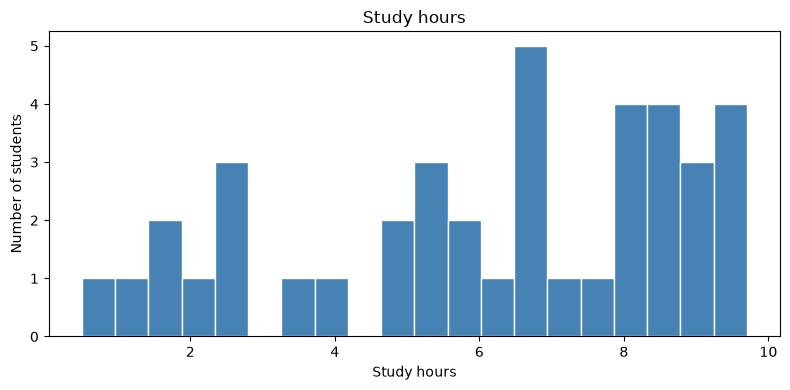

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(students["Study_Hours"], bins=20, color="steelblue", edgecolor="white")
ax.set_title("Study hours")
ax.set_xlabel("Study hours")
ax.set_ylabel("Number of students")
fig.tight_layout()
plt.show()


### Attendance

How is attendance spread?


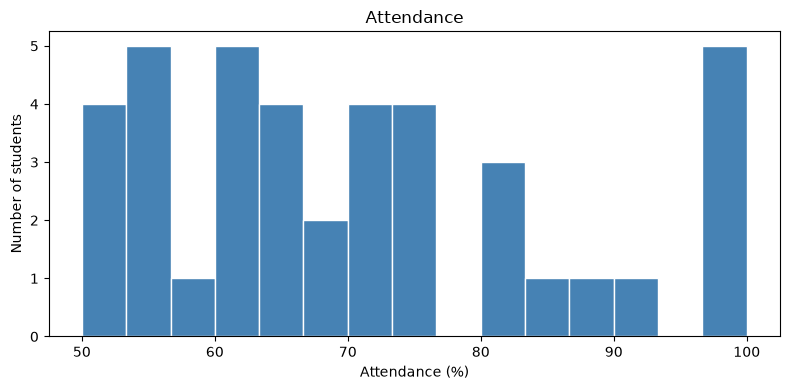

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(students["Attendance"], bins=15, color="steelblue", edgecolor="white")
ax.set_title("Attendance")
ax.set_xlabel("Attendance (%)")
ax.set_ylabel("Number of students")
fig.tight_layout()
plt.show()


### Assignment score

How are the assignment marks spread?


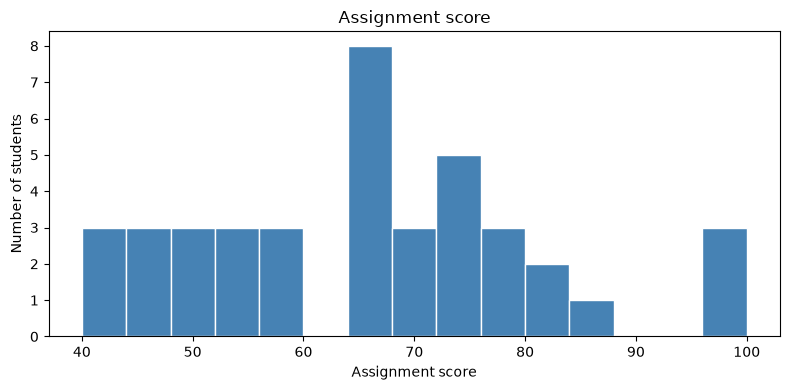

In [9]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(students["Assignment_Score"], bins=15, color="steelblue", edgecolor="white")
ax.set_title("Assignment score")
ax.set_xlabel("Assignment score")
ax.set_ylabel("Number of students")
fig.tight_layout()
plt.show()


### Passed

How many students passed? This is the column the models will predict. The two bars are the only values in the column: 0 and 1.


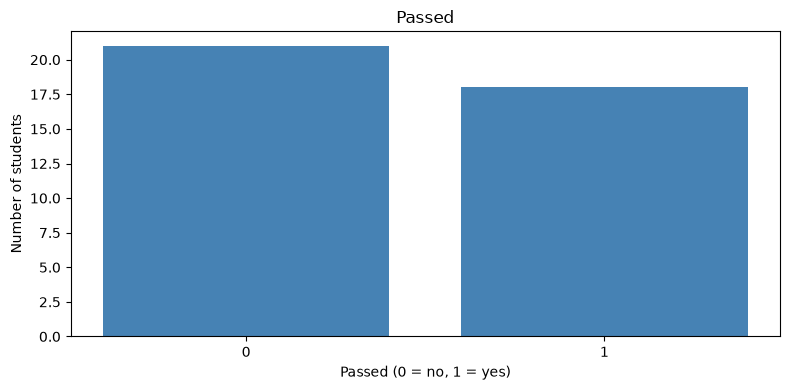

In [10]:
passed_counts = students["Passed"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(passed_counts.index.astype(int).astype(str), passed_counts.values, color="steelblue")
ax.set_title("Passed")
ax.set_xlabel("Passed (0 = no, 1 = yes)")
ax.set_ylabel("Number of students")
fig.tight_layout()
plt.show()


Study hours, attendance, and assignment score all vary from student to student. `Passed` takes two values, and both values appear. The next charts ask whether the three inputs move with that 0 or 1.


## 4. Bivariate charts

Bivariate means two columns at a time. Each chart below puts one input on the horizontal axis and `Passed` on the vertical axis.

Points sit on 0 and on 1, because those are the only answers. A relationship shows up as more 1s toward one end of the horizontal axis. The correlation is a single number for that relationship: positive when higher inputs line up with passing. Values nearer 1 are stronger.


### Study hours and passing

Do students who study longer pass more often?


Correlation of study hours and Passed: 0.793


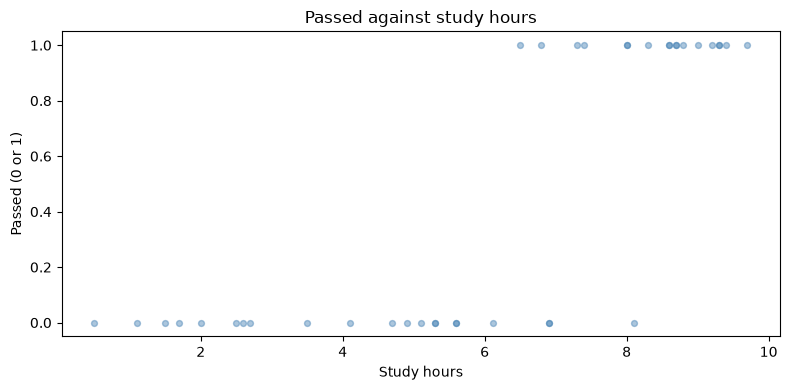

In [11]:
print(
    "Correlation of study hours and Passed:",
    round(students["Study_Hours"].corr(students["Passed"]), 3),
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(students["Study_Hours"], students["Passed"], color="steelblue", alpha=0.45, s=18)
ax.set_title("Passed against study hours")
ax.set_xlabel("Study hours")
ax.set_ylabel("Passed (0 or 1)")
fig.tight_layout()
plt.show()


### Attendance and passing

Do students with higher attendance pass more often?

A few points sit between the whole percentages. Those are the rows filled with the mean.


Correlation of attendance and Passed: 0.172


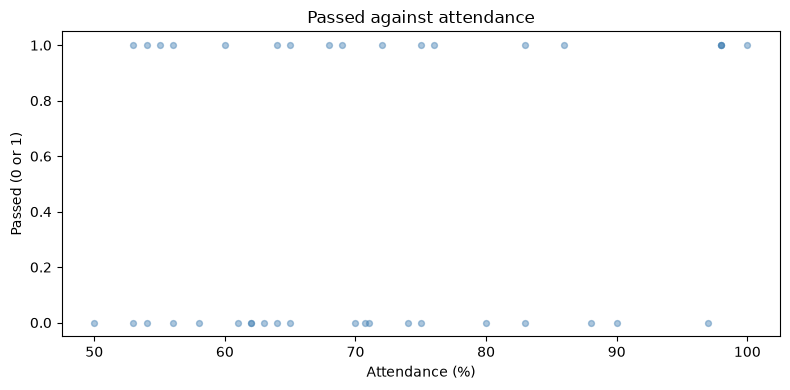

In [12]:
print(
    "Correlation of attendance and Passed:",
    round(students["Attendance"].corr(students["Passed"]), 3),
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(students["Attendance"], students["Passed"], color="steelblue", alpha=0.45, s=18)
ax.set_title("Passed against attendance")
ax.set_xlabel("Attendance (%)")
ax.set_ylabel("Passed (0 or 1)")
fig.tight_layout()
plt.show()


### Assignment score and passing

Do higher assignment marks line up with passing?


Correlation of assignment score and Passed: 0.016


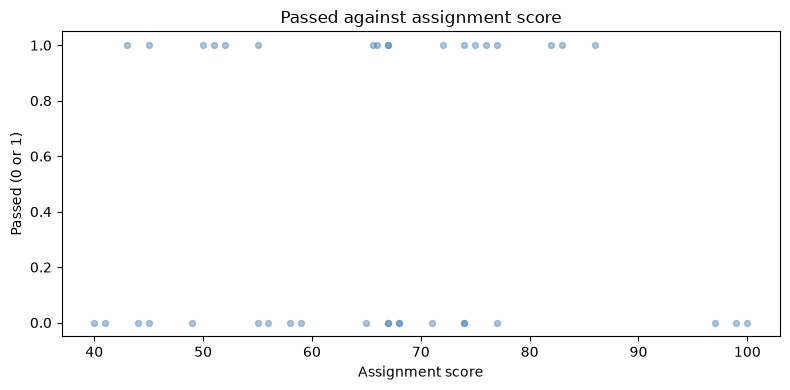

In [13]:
print(
    "Correlation of assignment score and Passed:",
    round(students["Assignment_Score"].corr(students["Passed"]), 3),
)

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(
    students["Assignment_Score"],
    students["Passed"],
    color="steelblue",
    alpha=0.45,
    s=18,
)
ax.set_title("Passed against assignment score")
ax.set_xlabel("Assignment score")
ax.set_ylabel("Passed (0 or 1)")
fig.tight_layout()
plt.show()


All three correlations are positive. Longer study, higher attendance, and a higher assignment score line up with `Passed` = 1. The clouds are two bands, and the band at 1 fills in as the input rises.

A model that aims a number between 0 and 1 at those bands has something real to learn. Regression is a reasonable next step.


## 5. Multivariate charts

Multivariate means more than two columns at once.

Each chart keeps study hours and `Passed`, and adds a third column as the color of the point. On the top band (`Passed` = 1), look at whether the color differs from the bottom band. If it does, that third column still carries information the model should use.


### Study hours, passing, and attendance

Among students with similar study hours, does higher attendance still go with passing?


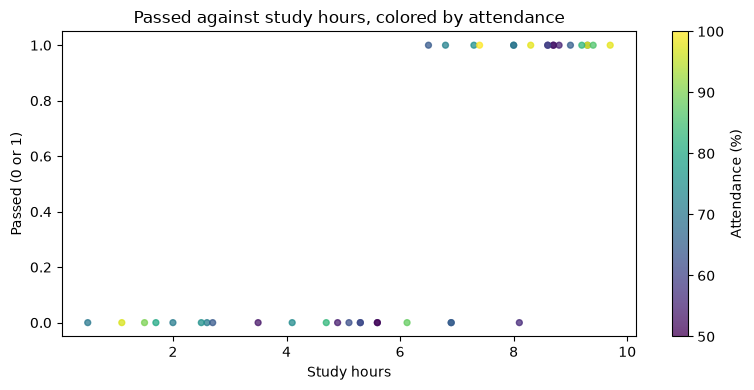

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
points = ax.scatter(
    students["Study_Hours"],
    students["Passed"],
    c=students["Attendance"],
    cmap="viridis",
    alpha=0.75,
    s=18,
)
fig.colorbar(points, ax=ax, label="Attendance (%)")
ax.set_title("Passed against study hours, colored by attendance")
ax.set_xlabel("Study hours")
ax.set_ylabel("Passed (0 or 1)")
fig.tight_layout()
plt.show()


### Study hours, passing, and assignment score

Among students with similar study hours, does a higher assignment score still go with passing?


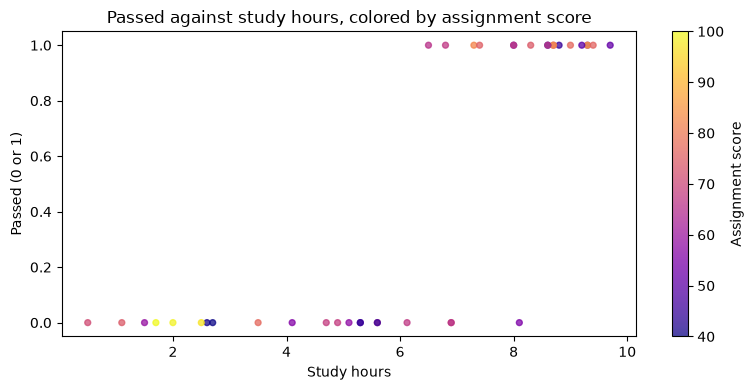

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
points = ax.scatter(
    students["Study_Hours"],
    students["Passed"],
    c=students["Assignment_Score"],
    cmap="plasma",
    alpha=0.75,
    s=18,
)
fig.colorbar(points, ax=ax, label="Assignment score")
ax.set_title("Passed against study hours, colored by assignment score")
ax.set_xlabel("Study hours")
ax.set_ylabel("Passed (0 or 1)")
fig.tight_layout()
plt.show()


The pass band and the fail band are still there, and the color is arranged through them. Attendance and assignment score still matter once study hours are taken into account. The three inputs can go into one regression together.


## 6. Linear regression

Linear regression fits one weight per input:

`Passed = intercept + (study weight × study hours) + (attendance weight × attendance) + (assignment weight × assignment score)`

A positive weight raises the predicted value toward passing. A negative weight lowers it. The weights are chosen on the training students.

The table is split once here. 80% of the students are for training. 20% are held out as the test set. Every model below uses this same split, so the three scores can be compared.

The score functions are imported in this block. Later models call the same three.


In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Student_ID stays out. It does not describe the student.
features = ["Study_Hours", "Attendance"]
target = "Assignment_Score"  

X = students[features]
y = students[target]

# random_state keeps the same students in the test set on every run.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Training students:", len(X_train))
print("Test students:", len(X_test))

results = []

def print_scores(model_name, y_true, y_pred):
    # MAE, MSE, and R2. The formulas are at the top of the notebook.
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(model_name)
    print("MAE:", round(mae, 3))
    print("MSE:", round(mse, 3))
    print("R2:", round(r2, 3))
    results.append({"Model": model_name, "MAE": mae, "MSE": mse, "R2": r2})

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
pred_linear = linear_model.predict(X_test)
print_scores("Linear regression", y_test, pred_linear)

print("Intercept:", round(linear_model.intercept_, 2))
print("Weight for Study_Hours:", round(linear_model.coef_[0], 4))
print("Weight for Attendance:", round(linear_model.coef_[1], 4))



Training students: 32
Test students: 8
Linear regression
MAE: 11.241
MSE: 195.514
R2: -0.362
Intercept: 59.87
Weight for Study_Hours: -0.9065
Weight for Attendance: 0.1847


Read the signs against the scatter charts. Study hours, attendance, and assignment score should each have a positive weight.

The next chart is the test students only. The horizontal axis is the real value of `Passed`. The vertical axis is the predicted value. The gray line is a perfect prediction. Points close to that line are students the model scored well.


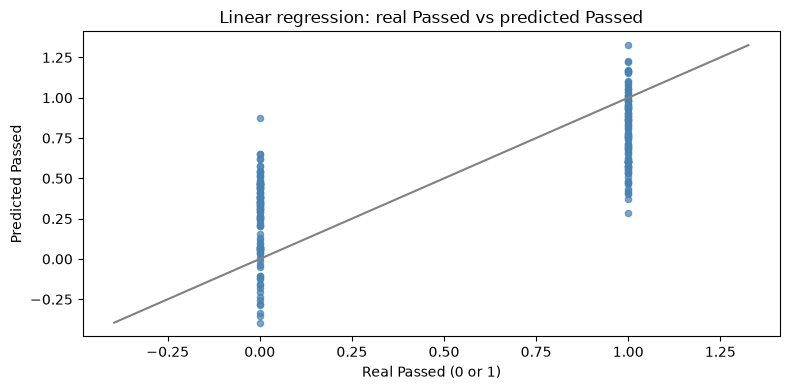

In [16]:
low = min(y_test.min(), pred_linear.min())
high = max(y_test.max(), pred_linear.max())

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(y_test, pred_linear, color="steelblue", alpha=0.7, s=20)
ax.plot([low, high], [low, high], color="gray")
ax.set_title("Linear regression: real Passed vs predicted Passed")
ax.set_xlabel("Real Passed (0 or 1)")
ax.set_ylabel("Predicted Passed")
fig.tight_layout()
plt.show()


## 7. Polynomial regression, degrees 2 to 10

Polynomial regression builds extra columns from the three inputs: powers and products, up to a chosen degree. Degree 2 can bend a little. Degree 10 can bend a lot.

The loop fits every degree from 2 to 10 on the same training students, and scores it on the same test students.

Two steps keep the fit under control.

- The inputs are scaled first. Attendance and assignment score are in the tens and hundreds, and a 10th power of a raw score would be an enormous number.
- Each degree is then fit with **Ridge** regression: linear regression plus a small penalty (`alpha=1`). High powers are almost repeats of the original columns. Without the penalty the predicted values explode and the scores stop meaning anything. The penalty keeps the predictions on a sensible scale, so the chart can show the best degree.

The scaled columns are a new table. `X_train` itself stays as it was, for the models that come later.

A higher degree fits the training students a little more tightly. Judge the degree by the test scores. Small ups and downs from one degree to the next can happen. The best degree is the one with the highest test R² and the lowest test MAE and MSE.


In [17]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

degrees = []
test_mae = []
test_mse = []
test_r2 = []
train_r2 = []

for degree in range(2, 11):
    # Fit the scaler on the training students only, then apply it to the test students.
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # Powers and products up to this degree.
    poly = PolynomialFeatures(degree=degree)
    X_train_poly = poly.fit_transform(X_train_scaled)
    X_test_poly = poly.transform(X_test_scaled)

    # alpha=1 is the penalty that keeps high degrees from exploding.
    poly_model = Ridge(alpha=1.0)
    poly_model.fit(X_train_poly, y_train)
    pred_poly = poly_model.predict(X_test_poly)

    mae = mean_absolute_error(y_test, pred_poly)
    mse = mean_squared_error(y_test, pred_poly)
    r2 = r2_score(y_test, pred_poly)
    r2_train = r2_score(y_train, poly_model.predict(X_train_poly))

    degrees.append(degree)
    test_mae.append(mae)
    test_mse.append(mse)
    test_r2.append(r2)
    train_r2.append(r2_train)

    print(
        "Degree", degree,
        " MAE:", round(mae, 3),
        " MSE:", round(mse, 3),
        " R2:", round(r2, 3),
        " Train R2:", round(r2_train, 3),
    )

degree_scores = pd.DataFrame({
    "Degree": degrees,
    "MAE": test_mae,
    "MSE": test_mse,
    "R2": test_r2,
    "Train R2": train_r2,
})

best_pos = test_r2.index(max(test_r2))
best_degree = degrees[best_pos]
print("Best degree by test R2:", best_degree)
print("Degree with the lowest test MAE:", degrees[test_mae.index(min(test_mae))])
print("Degree with the lowest test MSE:", degrees[test_mse.index(min(test_mse))])

# Keep the best degree for the comparison at the end.
results.append({
    "Model": f"Polynomial (degree {best_degree})",
    "MAE": test_mae[best_pos],
    "MSE": test_mse[best_pos],
    "R2": test_r2[best_pos],
})

degree_scores.round(3)


Degree 2  MAE: 0.285  MSE: 0.115  R2: 0.538  Train R2: 0.602
Degree 3  MAE: 0.238  MSE: 0.098  R2: 0.61  Train R2: 0.681
Degree 4  MAE: 0.237  MSE: 0.101  R2: 0.594  Train R2: 0.688
Degree 5  MAE: 0.214  MSE: 0.095  R2: 0.62  Train R2: 0.709
Degree 6  MAE: 0.217  MSE: 0.097  R2: 0.613  Train R2: 0.719
Degree 7  MAE: 0.219  MSE: 0.101  R2: 0.597  Train R2: 0.73
Degree 8  MAE: 0.24  MSE: 0.131  R2: 0.474  Train R2: 0.744
Degree 9  MAE: 0.239  MSE: 0.15  R2: 0.4  Train R2: 0.754
Degree 10  MAE: 0.246  MSE: 0.136  R2: 0.456  Train R2: 0.766
Best degree by test R2: 5
Degree with the lowest test MAE: 5
Degree with the lowest test MSE: 5


,Degree,MAE,MSE,R2,Train R2
0,2,0.285,0.115,0.538,0.602
1,3,0.238,0.098,0.610,0.681
2,4,0.237,0.101,0.594,0.688
3,5,0.214,0.095,0.620,0.709
4,6,0.217,0.097,0.613,0.719
5,7,0.219,0.101,0.597,0.730
6,8,0.240,0.131,0.474,0.744
7,9,0.239,0.150,0.400,0.754
8,10,0.246,0.136,0.456,0.766


The next three charts show those scores, one chart per score. The dashed line marks the degree with the highest test R².

On the MAE chart and the MSE chart, the best degree is the low point. On the R² chart, the best degree is the high point. In the table, train R² creeps up as the degree rises, while the test scores get worse after the best degree.


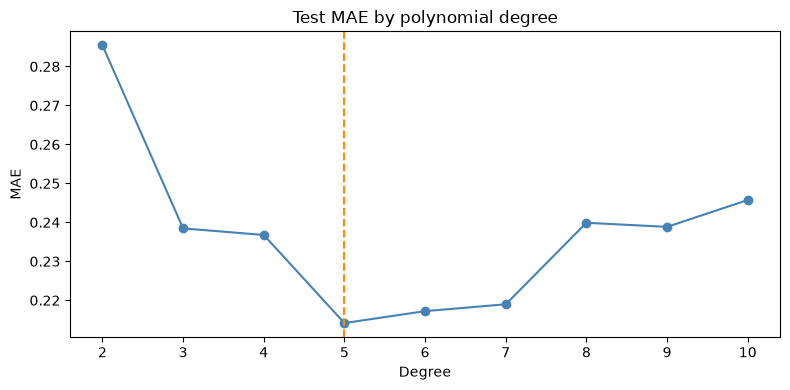

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(degrees, test_mae, marker="o", color="steelblue")
ax.axvline(best_degree, color="darkorange", linestyle="--")
ax.set_title("Test MAE by polynomial degree")
ax.set_xlabel("Degree")
ax.set_ylabel("MAE")
ax.set_xticks(degrees)
fig.tight_layout()
plt.show()


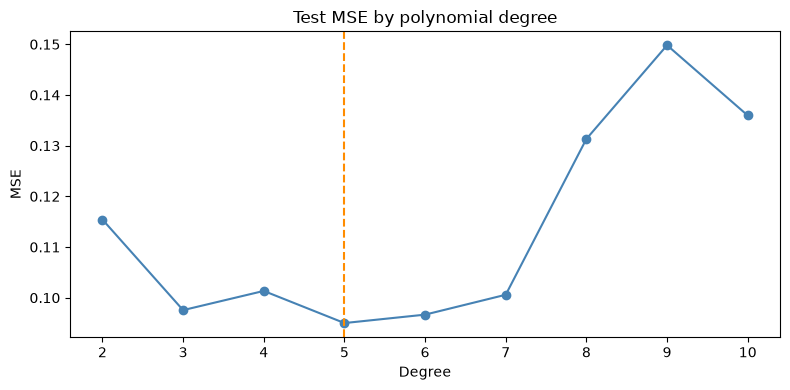

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(degrees, test_mse, marker="o", color="steelblue")
ax.axvline(best_degree, color="darkorange", linestyle="--")
ax.set_title("Test MSE by polynomial degree")
ax.set_xlabel("Degree")
ax.set_ylabel("MSE")
ax.set_xticks(degrees)
fig.tight_layout()
plt.show()


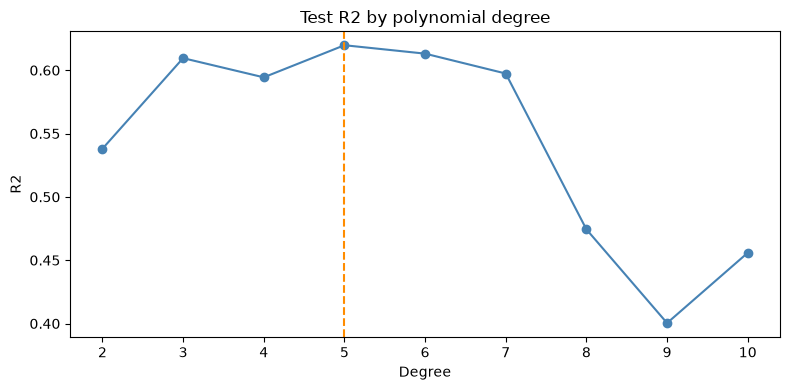

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(degrees, test_r2, marker="o", color="steelblue")
ax.axvline(best_degree, color="darkorange", linestyle="--")
ax.set_title("Test R2 by polynomial degree")
ax.set_xlabel("Degree")
ax.set_ylabel("R2")
ax.set_xticks(degrees)
fig.tight_layout()
plt.show()


## 8. Decision tree regression

A decision tree asks a chain of yes/no questions, such as whether study hours are above a cut or attendance is below a cut. Each student ends in a leaf, and the leaf's prediction is the average `Passed` value of the training students who landed there.

`max_depth=6` stops the tree after six questions. A deeper tree can memorize the training students and then miss the test students.


In [21]:
from sklearn.tree import DecisionTreeRegressor

tree_model = DecisionTreeRegressor(max_depth=6, random_state=42)
tree_model.fit(X_train, y_train)
pred_tree = tree_model.predict(X_test)
print_scores("Decision tree", y_test, pred_tree)


Decision tree
MAE: 0.209
MSE: 0.158
R2: 0.369


## 9. Random forest regression

A random forest grows many decision trees. Each tree sees a random sample of the training students. The prediction is the average of the trees.

Averaging keeps a single odd tree from dominating the prediction. `n_estimators=100` is the number of trees. `max_depth=8` limits how long each tree is.


In [22]:
from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=8,
    random_state=42,
)
forest_model.fit(X_train, y_train)
pred_forest = forest_model.predict(X_test)
print_scores("Random forest", y_test, pred_forest)


Random forest
MAE: 0.213
MSE: 0.119
R2: 0.526


## 10. Gradient boosting regression

Gradient boosting also uses trees, built one after another. Each new tree focuses on the students the earlier trees scored badly. The final prediction adds those trees together.

`learning_rate=0.1` keeps each new tree's correction small. `n_estimators=100` is the number of trees. `max_depth=3` keeps each tree short.


In [23]:
from sklearn.ensemble import GradientBoostingRegressor

gbr_model = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42,
)
gbr_model.fit(X_train, y_train)
pred_gbr = gbr_model.predict(X_test)
print_scores("Gradient boosting", y_test, pred_gbr)


Gradient boosting
MAE: 0.241
MSE: 0.11
R2: 0.559


## 11. XGBoost regression

XGBoost is a gradient boosting method with its own implementation. It builds the same kind of sequence: each new tree works on the remaining error.

The settings match the previous model (100 trees, learning rate 0.1, depth 3) so the two scores are comparable. `reg:squarederror` tells XGBoost that the target is a number and the loss is squared error, the same idea as MSE.


In [24]:
from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    objective="reg:squarederror",
    random_state=42,
)
xgb_model.fit(X_train, y_train)
pred_xgb = xgb_model.predict(X_test)
print_scores("XGBoost", y_test, pred_xgb)


XGBoost
MAE: 0.24
MSE: 0.11
R2: 0.561


## 12. Support vector regression

Support vector regression (SVR) looks for a function with a tube around it. Misses smaller than `epsilon` sit inside the tube and are treated as close enough. `C` controls how hard the model tries to stay inside that tube. The RBF kernel lets the function curve.

SVR uses distances between students. Assignment score runs up to 100 and study hours run up to 10, so the assignment score would dominate the distance. Scaling puts the three inputs on a similar range. The scaler is fit on the training students only.


In [25]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

svr_scaler = StandardScaler()
X_train_scaled = svr_scaler.fit_transform(X_train)
X_test_scaled = svr_scaler.transform(X_test)

# epsilon is on the 0-to-1 pass scale. Misses smaller than 0.1 sit inside the tube.
svr_model = SVR(kernel="rbf", C=10, epsilon=0.1)
svr_model.fit(X_train_scaled, y_train)
pred_svr = svr_model.predict(X_test_scaled)
print_scores("SVR", y_test, pred_svr)


SVR
MAE: 0.199
MSE: 0.101
R2: 0.595


## 13. Compare the models

The table collects the test MAE, test MSE, and test R² for every model. The polynomial row is the best degree from the charts above.

The three bar charts show the same numbers, one chart per score. A shorter bar is better for MAE and MSE. A taller bar is better for R².


In [26]:
comparison = pd.DataFrame(results)
comparison["MAE"] = comparison["MAE"].round(3)
comparison["MSE"] = comparison["MSE"].round(3)
comparison["R2"] = comparison["R2"].round(3)
comparison


,Model,MAE,MSE,R2
0,Linear regression,0.283,0.112,0.551
1,Polynomial (degree 5),0.214,0.095,0.620
2,Decision tree,0.209,0.158,0.369
3,Random forest,0.213,0.119,0.526
4,Gradient boosting,0.241,0.110,0.559
5,XGBoost,0.240,0.110,0.561
6,SVR,0.199,0.101,0.595


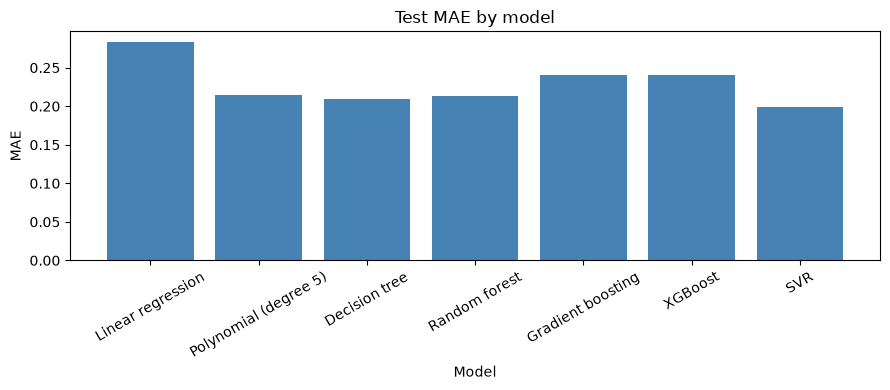

In [27]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(comparison["Model"], comparison["MAE"], color="steelblue")
ax.set_title("Test MAE by model")
ax.set_xlabel("Model")
ax.set_ylabel("MAE")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()


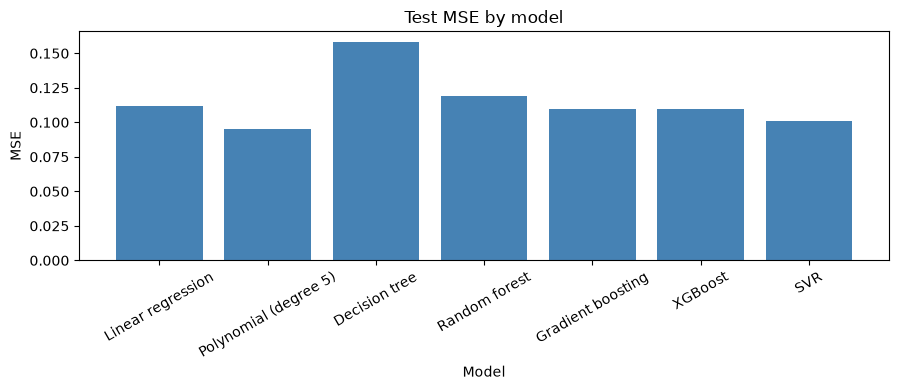

In [28]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(comparison["Model"], comparison["MSE"], color="steelblue")
ax.set_title("Test MSE by model")
ax.set_xlabel("Model")
ax.set_ylabel("MSE")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()


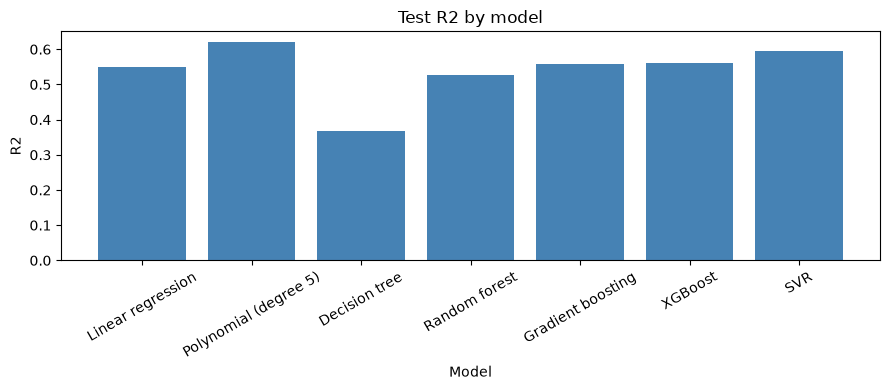

In [29]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(comparison["Model"], comparison["R2"], color="steelblue")
ax.set_title("Test R2 by model")
ax.set_xlabel("Model")
ax.set_ylabel("R2")
ax.tick_params(axis="x", rotation=30)
fig.tight_layout()
plt.show()


In [30]:
best_r2_row = comparison["R2"].idxmax()
best_mae_row = comparison["MAE"].idxmin()
best_mse_row = comparison["MSE"].idxmin()

print("Highest test R2:", comparison.loc[best_r2_row, "Model"])
print("Lowest test MAE:", comparison.loc[best_mae_row, "Model"])
print("Lowest test MSE:", comparison.loc[best_mse_row, "Model"])


Highest test R2: Polynomial (degree 5)
Lowest test MAE: SVR
Lowest test MSE: Polynomial (degree 5)


## Takeaways

- The raw file has blank cells in `Study_Hours` and `Attendance` only. Each blank was filled with that column's mean.
- A few rows were exact copies. `drop_duplicates` removed the extra copies.
- The univariate charts show that the three inputs vary, and that `Passed` is a mix of 0s and 1s.
- The bivariate charts show study hours, attendance, and assignment score all rising with passing. That is enough structure for a regression.
- The multivariate charts show that attendance and assignment score still shift who passes when study hours are held in view, so the model can use all three inputs.
- Among polynomial degrees 2 to 10, the best degree is the low point of the MAE and MSE charts and the high point of the R² chart. Higher degrees score worse on the test students.
- Read the last three bars together with the table. Lower MAE, lower MSE, and higher R² mark the stronger model on the students it did not train on.
